# L7 Skill：把预报经验做成技能包

<!-- course-meta: real-llm -->

从这一讲开始，智能体换成 deepagents 的 `create_deep_agent`。

Skill 和系统提示词的区别：

| | 系统提示词 | Skill |
|---|---|---|
| 加载时机 | 每次都全文加载 | 平时只露出名字和简介，用到时才读全文 |
| 适合放 | 角色、通用规则 | 某个专题的规范、步骤、参考表 |
| 维护 | 一大段，改一处牵一片 | 一个专题一个文件夹，各管各的 |

课程包的 `skills/` 下已有两个示例：`tmax-description`（最高气温描述规范）、`typhoon-grade`（台风等级标准）。

这一讲要用**真实模型**，`.env` 里的 `MAIN_API_KEY` 必须填好（Skill 会不会被读，取决于模型自己的判断）。
暂时没有 Key，就先看同目录的 `99_假模型剧本.ipynb`：那里用预设剧本演示同样的流程。

In [1]:
# 改了 common/、weather_tools/ 里的代码后自动重新加载，不用重启内核
%load_ext autoreload
%autoreload 2

from deepagents import create_deep_agent
from deepagents.backends import FilesystemBackend

from common import llm
from common.paths import COURSE_ROOT, SKILLS_DIR
from common.trace import show, tool_calls

for d in sorted(SKILLS_DIR.iterdir()):
    print(d.name, "→", (d / "SKILL.md").read_text(encoding="utf-8").splitlines()[2][:80])

tmax-description → description: 广东最高气温分布业务描述规范。当用户要求“写最高气温分布描述”“描述今天的最高气温”或需要把最高气温实况图写成文字时使用。
typhoon-grade → description: 中国气象局（CMA）热带气旋强度等级标准。需要根据风速判断台风等级、核对台风强度描述、或在报告中写台风等级时使用。


## 1. SKILL.md 的结构

- 开头 `---` 之间是“名片”：`name` 和 `description`。智能体只看名片决定要不要用，**所以 description 要写清“什么时候用”**。
- 正文写步骤和规范，用到时才读。

In [2]:
print((SKILLS_DIR / "typhoon-grade" / "SKILL.md").read_text(encoding="utf-8"))

---
name: typhoon-grade
description: 中国气象局（CMA）热带气旋强度等级标准。需要根据风速判断台风等级、核对台风强度描述、或在报告中写台风等级时使用。
---

# 热带气旋强度等级（GB/T 19201-2006）

| 等级 | 缩写 | 底层中心附近最大平均风速 (m/s) | 风力 |
|---|---|---|---|
| 热带低压 | TD | 10.8～17.1 | 6～7 级 |
| 热带风暴 | TS | 17.2～24.4 | 8～9 级 |
| 强热带风暴 | STS | 24.5～32.6 | 10～11 级 |
| 台风 | TY | 32.7～41.4 | 12～13 级 |
| 强台风 | STY | 41.5～50.9 | 14～15 级 |
| 超强台风 | SuperTY | ≥51.0 | 16 级及以上 |

## 步骤

1. 用“中心附近最大平均风速”判断，不用阵风。台风接口里“中心风力”是平均风，“中心最大风力”是阵风。
2. 风速落在两档之间的缝隙（如 17.15）时，按“≥17.2 才算热带风暴”处理。
3. 写报告时等级和风速一起写，例如“台风级（33 米/秒，12 级）”。




## 2. 接到智能体上

`backend=FilesystemBackend(root_dir=课程包目录, virtual_mode=True)` 让智能体能读课程包里的文件；
`skills=["/skills/"]` 告诉它技能包在哪。`virtual_mode=True` 限制它只能访问课程包目录内的文件。

In [3]:
def build_agent(model, skills=True):
    return create_deep_agent(
        model=model,
        system_prompt="你是广东省气象台的预报助手，用中文回答。",
        skills=["/skills/"] if skills else None,
        backend=FilesystemBackend(root_dir=str(COURSE_ROOT), virtual_mode=True),
    )


model = llm.main_llm()
r = build_agent(model).invoke({"messages": [{"role": "user", "content": "台风中心最大风速 23 米/秒，阵风 28 米/秒，是什么等级？"}]})
show(r, max_tool_chars=200)
print("读取了哪些文件：", [c["args"].get("file_path") for c in tool_calls(r) if c["name"] == "read_file"])

[1] 用户：台风中心最大风速 23 米/秒，阵风 28 米/秒，是什么等级？

[2] 模型决定调用工具 read_file，参数 {'file_path': '/skills/typhoon-grade/SKILL.md', 'limit': 1000}
[2] 模型决定调用工具 ls，参数 {'path': '/skills'}

[3] 工具 read_file 返回：@@ lines 1-22 of 22 @@
---
name: typhoon-grade
description: 中国气象局（CMA）热带气旋强度等级标准。需要根据风速判断台风等级、核对台风强度描述、或在报告中写台风等级时使用。
---

# 热带气旋强度等级（GB/T 19201-2006）

| 等级 | 缩写 | 底层中心附近最大平均风速 (m/s) | 风力 |
|---|---|-……（共 564 字，已截断）

[4] 工具 ls 返回：['/skills/tmax-description/', '/skills/typhoon-grade/']

[5] 模型回答：**热带风暴级（23 米/秒，9 级）**

判断依据（GB/T 19201-2006，中国气象局标准）：

- 等级判定应依据**底层中心附近最大平均风速**，也就是你给出的 23 米/秒；17.2～24.4 米/秒属于**热带风暴**（TS）这一等级。
- 23 米/秒对应风力**9 级**（9 级风速范围 20.8～24.4 米/秒）。
- 阵风 28 米/秒**不参与定级**，只作为强度描述的补充参考，可写为“阵风 28 米/秒（10 级）”。

报告中建议写为：**热带风暴级（23 米/秒，9 级）**；若要更完整，可写“中心附近最大平均风力 9 级（23 米/秒），阵风 10 级（28 米/秒）”。

读取了哪些文件： ['/skills/typhoon-grade/SKILL.md']


检查点：

- 智能体读了 `typhoon-grade/SKILL.md` 吗？
- 它用的是平均风 23，还是阵风 28？（23 是热带风暴，28 会被判成强热带风暴。）

## 3. 无关问题不应触发

问“现在几点”，智能体不应该去读台风等级的技能。

In [4]:
model = llm.main_llm()
r = build_agent(model).invoke({"messages": [{"role": "user", "content": "现在几点？"}]})
print("读取的文件：", [c["args"].get("file_path") for c in tool_calls(r) if c["name"] == "read_file"])

读取的文件： []


## 4. 练习：写你自己的 Skill

1. 选一项你最熟悉的业务经验（例如“台风等级判断”“回南天判断要点”“龙舟水期间强降水关注点”“寒潮预警发布条件”）。
2. 先口述给 workbuddy, codex 或者Claude Code，让它用 `skill-creator` 的格式整理成 `skills/<英文名>/SKILL.md`。
3. 你自己修改：description 写清什么时候用；正文写成步骤。
4. 回到第 2 节，问一个应该触发它的问题，再问一个不该触发的问题。



# 5. 练习：对比实验
用 L2 的最高气温图，`skills=True` 和 `skills=False` 各写一段描述，按 9 项指标打分。
导出大模型评分表格，看看哪些是主要扣分项， 是否能继续优化Skill 让模型写得更好。判断是模型的能力问题，还是skill引导的缺陷。

### 对比实验：最高气温描述

两组使用同一张最高气温图和同一份视觉模型读图结果，只改变 `skills`。判官根据对应的站点真值 CSV 和 L2 九项标准评分。需要配置 `MAIN_API_KEY` 和 `VLM_API_KEY`；单次结果不能证明 Skill 一定提高得分。

本图统计时段为 2023-12-31 20 时至 2024-01-01 20 时。

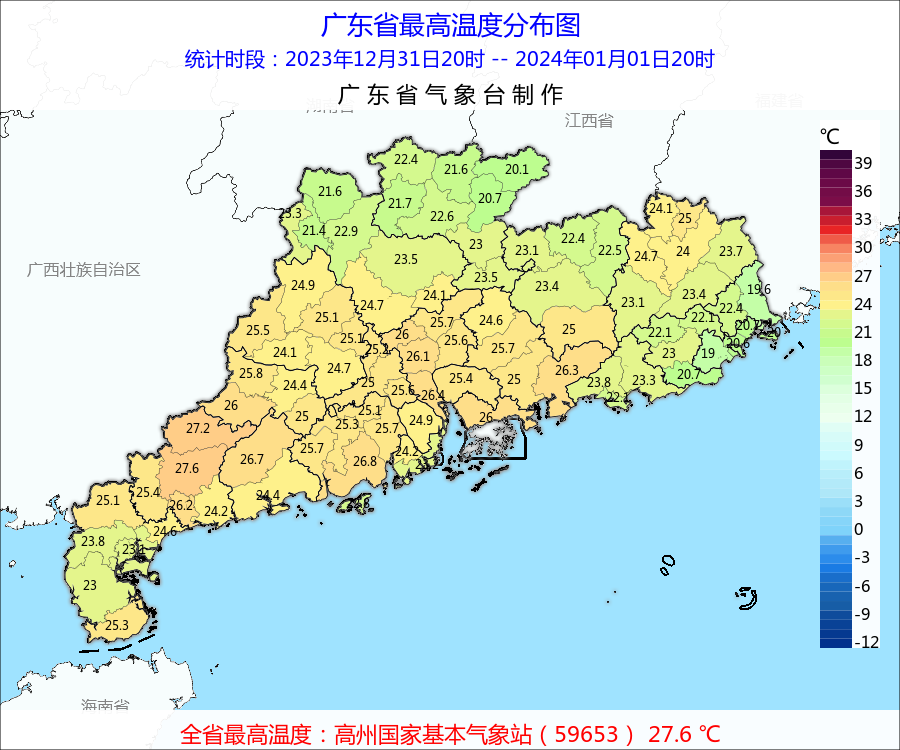

视觉模型读图结果（请对照原图核验）：
 根据图片中的图表及文字标注，信息提取如下：

### 一、全省最高温度及所在市县
* **全省最高气温：** **27.6 ℃**
* **所在市县及站点：** **高州**（高州国家基本气象站，站号 59653，行政上隶属于茂名市）

---

### 二、各区域最高气温范围
全省最高气温总体介于 **19.0 ℃ ～ 27.6 ℃** 之间，呈现“南高北低、西南高东北低”的分布特征：

1. **粤西地区（茂名、阳江、湛江、云浮等）：**
   * **气温范围：** 普遍在 **23.0 ℃ ～ 27.6 ℃**。
   * **特征：** 是全省气温最高的区域，高州（27.6 ℃）、信宜（27.2 ℃）、阳江（26.7 ℃）等地温度全省领先；雷州半岛南部和沿海略低，在 23.0 ℃ ～ 25.3 ℃ 之间。

2. **珠江三角洲地区（广州、佛山、东莞、深圳、惠州、中山、珠海等）：**
   * **气温范围：** 普遍在 **24.0 ℃ ～ 26.4 ℃**。
   * **特征：** 气温较为温暖均匀，大部在 25 ℃ 左右（如广州 25.7 ℃、东莞 25.4 ℃、深圳 25.0 ℃、珠海 26.0 ℃）。

3. **粤北地区（清远、韶关等）：**
   * **气温范围：** 普遍在 **20.1 ℃ ～ 23.5 ℃**。
   * **特征：** 受冷空气影响相对明显，气温偏低，北部的南雄（20.1 ℃）、始兴（20.7 ℃）、连州（21.6 ℃）等地较低。

4. **粤东地区（河源、梅州、汕尾、揭阳、潮州、汕头等）：**
   * **气温范围：** 内陆山区在 **22.4 ℃ ～ 25.0 ℃**，沿海地区在 **19.0 ℃ ～ 23.8 ℃**。
   * **特征：** 潮汕沿海气温相对全省偏低，局部站点录得 19.0 ℃ ～ 20.6 ℃（如澄海/汕头附近 19.0 ℃、饶平 19.6 ℃）。

---

*注：汕头、潮州及珠江口近海个别海岛气象站由于数字重叠或字体过小略有模糊（如汕头市区附近部分站点数值约在 20～21 ℃ 之间），但不影响整体区间判定。*


In [5]:
import json
from IPython.display import Image, Markdown, display
from common.paths import DATA_DIR
from common.trace import final_text
from lessons_import import load_lesson_module
from weather_tools.vision import ask_image

scoring = load_lesson_module("L02_提示词基础", "scoring")
D = DATA_DIR / "tmax_desc"
tmax_dir = DATA_DIR / "tmax"
image_name = "hs_temp_max_from20_2024010120"
img = tmax_dir / "images" / f"{image_name}.png"
truth_path = tmax_dir / "truth" / f"{image_name}.csv"
display(Image(filename=str(img), width=600))

# 只读图，不在此处给出 Skill 中的写作规则；两组使用完全相同的素材。
facts = ask_image(img, "请读取图中广东各区域的最高气温范围及全省最高值、所在市县；看不清的内容请注明，不要编造。")
print("视觉模型读图结果（请对照原图核验）：\n", facts)

In [6]:
request = f"""请根据以下最高气温图的读图结果，写一段广东最高气温分布的业务描述。
图示统计时段为 2023-12-31 20 时至 2024-01-01 20 时。只使用提供的资料，无法确认的信息不要编造。

读图结果：
{facts}"""

results = {}
for enabled in (False, True):
    result = build_agent(model, skills=enabled).invoke(
        {"messages": [{"role": "user", "content": request}]}
    )
    results[enabled] = final_text(result)
    print(f"\n--- skills={enabled} ---\n{results[enabled]}")
    print("读取的文件：", [c["args"].get("file_path") for c in tool_calls(result)
                         if c["name"] == "read_file"])


--- skills=False ---
## 广东省最高气温分布业务描述

**统计时段：2023年12月31日20时—2024年1月1日20时（24小时）**

**一、总体情况**

该时段全省最高气温介于 19.0～27.6 ℃ 之间，平均来看，全省最高气温的分布呈现“西南高、东北低，沿海与内陆差异明显”的特征：粤西地区最高，珠三角次之，粤北和粤东的沿海地区偏低。全省最高气温出现在茂名高州（高州国家基本气象站，站号 59653），为 27.6 ℃；最低值出现在粤东潮汕沿海一带，为 19.0 ℃，全省各站最高气温极差 8.6 ℃。

**二、分区描述**

1. **粤西地区（茂名、阳江、湛江、云浮等）**：全省最高气温最高的区域，普遍为 23.0～27.6 ℃。高州 27.6 ℃、信宜 27.2 ℃、阳江 26.7 ℃ 等地温度居全省前列；雷州半岛南部及沿海一带略低，为 23.0～25.3 ℃。

2. **珠江三角洲地区（广州、佛山、东莞、深圳、惠州、中山、珠海等）**：气温较温暖且分布均匀，普遍为 24.0～26.4 ℃，大部分地区在 25 ℃ 左右，其中珠海 26.0 ℃、广州 25.7 ℃、东莞 25.4 ℃、深圳 25.0 ℃。

3. **粤北地区（清远、韶关等）**：受冷空气影响相对明显，气温偏低，普遍为 20.1～23.5 ℃，南雄 20.1 ℃、始兴 20.7 ℃、连州 21.6 ℃ 等北部站点为区域低值。

4. **粤东地区（河源、梅州、汕尾、揭阳、潮州、汕头等）**：内陆山区为 22.4～25.0 ℃，沿海地区为 19.0～23.8 ℃。潮汕沿海最高气温相对全省偏低，局部站点为 19.0～20.6 ℃，其中饶平 19.6 ℃，汕头、澄海附近为 19.0 ℃ 左右。

**三、说明**

汕头、潮州及珠江口近海个别海岛站点的标注数值因数字重叠或字体较小而略显模糊（汕头市区附近部分站点约在 20～21 ℃ 之间），但不影响上述区间判定；具体站点数值以实测资料为准。
读取的文件： []

--- skills=True ---
最高气温具体分布为：粤东沿海市县、粤北北部市县介于19～22℃之间，粤北其余市县、粤东内陆市县和湛江介于22～25℃之间，珠三角和粤西其余市县介于25～28℃之间，其中茂名高州录得全省最高气温27.6℃。
读取的文

### 按九项指标评分：LLM as Judge

判官不看图，使用与图片同名的站点真值 CSV、地理划分 CSV 和 L2 九项评分标准，分别评价两段描述。真值表包含站点气温、市县和区域信息；判官使用主模型（`MAIN_API_KEY`），评分和理由仍需人工复核。若资料不足以判断某项，判官可标记无法评分，此时不计算总分。

In [7]:
import pandas as pd

display(Markdown(scoring.score_sheet()))
criteria = (D / "task4_评分指标.md").read_text(encoding="utf-8")
geo = pd.read_csv(D / "地理划分_去除空列.csv", encoding="utf-8-sig").fillna("")
truth = pd.read_csv(truth_path, encoding="utf-8-sig")
required_columns = {"stationid", "tmax", "City", "County", "Region"}
if truth.empty or not required_columns.issubset(truth.columns):
    raise ValueError(f"站点真值为空或缺少字段：{truth_path}")
print("图片：", img.name, "；站点真值：", truth_path.name, "；站点数：", len(truth))

| 序号 | 指标 | 满分 | 权重 | 得分 |
|---|---|---|---|---|
| 1 | 最高气温数值准确性 | 1 | 5 |  |
| 2 | 最高气温地理准确性 | 2 | 10 |  |
| 3 | 温度区间准确性 | 5 | 20 |  |
| 4 | 温度区间不能重叠 | 1 | 10 |  |
| 5 | 地理范围不能重叠 | 1 | 10 |  |
| 6 | 地理和气温范围表述的完整性 | 1 | 10 |  |
| 7 | 气温范围聚类合理性 | 4 | 20 |  |
| 8 | 气温描述顺序 | 1 | 5 |  |
| 9 | 用语规范性 | 5 | 10 |  |

图片： hs_temp_max_from20_2024010120.png ；站点真值： hs_temp_max_from20_2024010120.csv ；站点数： 86


In [8]:
def judge_tmax(description):
    prompt = f"""你是广东最高气温描述的评分员。依据站点真值 CSV 和九项评分标准逐项评价待评描述。
站点真值中的 tmax 是最高气温（℃），City、County、Region 为站点地理信息；地理划分 CSV 用于辅助判断地理范围。
缺乏足够证据时，该项 score 填 null，说明缺少什么证据，不要猜测。
只返回 JSON 对象，键为字符串 "1" 到 "9"，每项格式为 {{"score": 数字或null, "reason": "评分依据"}}；分数使用评分标准的原始分值，不是权重分。

## 九项评分标准
{criteria}

## 图片对应的站点真值 CSV
{truth.to_csv(index=False)}

## 地理划分 CSV
{geo.to_csv(index=False)}

## 待评描述
{description}"""
    text = llm.main_llm().invoke(prompt).text
    start, end = text.find("{"), text.rfind("}")
    if start < 0 or end < start:
        raise ValueError(f"判官没有返回 JSON，请检查原始输出：{text}")
    data = json.loads(text[start:end + 1])
    if set(data) != {str(i) for i in range(1, 10)}:
        raise ValueError(f"判官必须返回 1～9 项，实际返回：{list(data)}")
    scores = {}
    for metric in scoring.METRICS:
        item = data[str(metric["id"])]
        value = item["score"]
        if value is not None:
            if isinstance(value, bool) or not isinstance(value, (int, float)) or not 0 <= value <= metric["max"]:
                raise ValueError(f"指标 {metric['id']} 分数超出范围：{value}")
            scores[metric["id"]] = value
        if not isinstance(item.get("reason"), str) or not item["reason"].strip():
            raise ValueError(f"指标 {metric['id']} 缺少评分依据")
    return data, scoring.total_score(scores) if len(scores) == 9 else None

judgements = {}
for enabled in (False, True):
    details, total = judge_tmax(results[enabled])
    judgements[enabled] = (details, total)
    print(f"\n--- skills={enabled} 判官评分 ---")
    display(pd.DataFrame([{
        "指标": m["name"], "原始分": details[str(m["id"])]["score"],
        "满分": m["max"], "权重": m["weight"],
        "评分依据": details[str(m["id"])]["reason"],
    } for m in scoring.METRICS]))
    print("加权总分：", f"{total} / 100" if total is not None else "证据不足，未计算")


--- skills=False 判官评分 ---


,指标,原始分,满分,权重,评分依据
0,最高气温数值准确性,1.0,1,5,描述称茂名高州27.6℃为全省最高，与真值最高tmax=27.6℃（高州站59653）完全一致。
1,最高气温地理准确性,2.0,2,10,真值最高气温唯一出现在茂名高州；描述给出“茂名高州”，地级市和区县均正确，且最高气温区县数量一致。
2,温度区间准确性,4.3,5,20,多数区间接近真值，如全省19.0～27.6℃、粤西23.0～27.6℃、雷州半岛南部23.0...
3,温度区间不能重叠,0.0,1,10,多个地理范围的温度区间存在明显重叠，例如粤西23.0～27.6℃与珠三角24.0～26.4℃...
4,地理范围不能重叠,0.0,1,10,描述的多个区域存在包含/重叠关系，如雷州半岛南部及沿海属于粤西，粤东的内陆山区、沿海地区以及...
5,地理和气温范围表述的完整性,1.0,1,10,粤西、珠三角、粤北、粤东四大区域及“等”基本覆盖全部地市，未见整块地理区域缺失；个别温度区间...
6,气温范围聚类合理性,2.0,4,20,使用了大类地理区域且部分聚类区间合理，但粤西23.0～27.6℃、粤东沿海19.0～23.8...
7,气温描述顺序,0.0,1,5,分区按粤西（高值）→珠三角→粤北→粤东排列，未按先描述特例或范围较小温度区间、最后描述普遍区...
8,用语规范性,2.0,5,10,存在“温度居全省前列”等非规范“气温”表达；多数分区用“普遍为……”而非“介于……之间”；附...


加权总分： 56.2 / 100

--- skills=True 判官评分 ---


,指标,原始分,满分,权重,评分依据
0,最高气温数值准确性,1.00,1,5,真值全省最高气温为茂名高州27.6℃，描述数值27.6℃完全正确。
1,最高气温地理准确性,2.00,2,10,最高气温地点为茂名高州，描述中地级市和区县名称均正确，且最高值地点数量一致。
2,温度区间准确性,3.86,5,20,按7个地理区域分别与真值比对后取平均：粤东沿海约4分、粤北北部约2分、粤北其余5分、粤东内陆...
3,温度区间不能重叠,1.00,1,10,19～22℃、22～25℃、25～28℃三个区间仅在端点相接，按评分标准不视为温度区间交叉重叠。
4,地理范围不能重叠,1.00,1,10,粤北北部与粤北其余、粤东沿海与粤东内陆、湛江与粤西其余等划分未见地理包含或重叠；最高值地点属...
5,地理和气温范围表述的完整性,1.00,1,10,描述覆盖了粤东、粤北、珠三角、湛江及粤西其余等区域，未发现遗漏某个地理区域的气温区间描述。
6,气温范围聚类合理性,3.00,4,20,三个温度区间宽度均为3℃，分类数量较少并优先使用大类地理区域；但粤北北部与粤东沿海同置于19...
7,气温描述顺序,1.00,1,5,主体按19～22℃、22～25℃、25～28℃由低到高描述，最高值作为其中特殊点附后，顺序基...
8,用语规范性,5.00,5,10,使用“气温”“介于……℃之间”等规范表达，无明显口语化、冗余提示语或格式错误。


加权总分： 90.4 / 100


## 6. 用正式规约版重新评估

完成第 5 节并保留当前内核运行结果后，再执行下面的替换单元格。它会先把当前简化版 `SKILL.md` 备份到 `outputs/`，再把课程目录下的备用正式版及原始规约复制到 `skills/tmax-description/`。完成评估后可用下方恢复单元格还原。不要在重新执行第 5 节之前覆盖内存中的基线结果。

正式版要求先分析再输出正式描述，而本实验要求一段描述；比较时统一用正式描述评分。使用同一张图、读图结果、提示词、模型和判官，检查正式版是否被读取，并对照无 Skill、简化版和正式版的分项分数。单次模型评分存在波动，应多次重复并人工复核。

In [9]:
from pathlib import Path
import shutil
import uuid
from common.paths import OUTPUT_DIR

formal_dir = COURSE_ROOT / "lessons" / "L07_Skill技能包" / "备用技能" / "tmax-description"
active_dir = SKILLS_DIR / "tmax-description"
formal_skill = (formal_dir / "SKILL.md").read_bytes()
active_skill = (active_dir / "SKILL.md").read_bytes()
if active_skill == formal_skill:
    raise RuntimeError("当前已是正式版；请先恢复简化版并完成第 5 节的基线实验。")
if True not in results or True not in judgements:
    raise RuntimeError("请先完成第 5 节的生成和评分，保留简化版结果。")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
backup_skill = OUTPUT_DIR / f"tmax-description-baseline-{uuid.uuid4().hex}.md"
backup_skill.write_bytes(active_skill)
# 将正式版所需的原始规约也一起复制，供模型按需查阅。
shutil.copytree(formal_dir, active_dir, dirs_exist_ok=True)
print("简化版已备份：", backup_skill)
print("正式版已安装：", active_dir / "SKILL.md")

简化版已备份： D:\github\LLM\agent_course\course\outputs\tmax-description-baseline-e8989f958f5a4766865fdc08e11db903.md
正式版已安装： D:\github\LLM\agent_course\course\skills\tmax-description\SKILL.md


In [10]:
# 重新构建智能体，确保它重新加载正式版 Skill。
formal_result = build_agent(model, skills=True).invoke(
    {"messages": [{"role": "user", "content": request}]}
)
formal_output = final_text(formal_result)
read_paths = [c["args"].get("file_path", "") for c in tool_calls(formal_result)
              if c["name"] == "read_file"]
print("正式版输出：\n", formal_output)
print("读取的文件：", read_paths)
formal_read = any(p.replace("\\", "/").endswith("/tmax-description/SKILL.md") for p in read_paths)
if not formal_read:
    print("注意：未观察到读取正式版 SKILL.md；本次不能归因于正式版 Skill。")

# 规约版可能带分析和代码块；评分时只评正式描述。
import re
blocks = re.findall(r"```气象图像分析\s*\n(.*?)```", formal_output, flags=re.DOTALL)
if len(blocks) != 1:
    raise ValueError("未找到唯一的‘气象图像分析’代码块；请检查输出后手动提取正式描述，再调用 judge_tmax。")
formal_description = blocks[0].strip()
formal_details, formal_total = judge_tmax(formal_description)

正式版输出：
 ## 一、读图资料梳理（统计时段：2023年12月31日20时—2024年1月1日20时）

- 全省最高气温介于 **19.0～27.6℃**，总体呈“南高北低、西南高东北低”的格局。
- 粤西地区（茂名、阳江、湛江、云浮）最高，为 23.0～27.6℃；
- 珠三角地区多为 24.0～26.4℃，全省最暖的南部地带在此集中；
- 粤北（韶关、清远）受冷空气影响，为 20.1～23.5℃，以偏北的南雄、始兴、连州最低；
- 粤东内陆为 22.4～25.0℃，但潮汕沿海一带仅为 19.0～23.8℃，是全省最低值所在。
- 全省最高值出现在 **茂名高州（高州国家基本气象站，站号 59653），为 27.6℃**。

按规约将全省最高气温连续分为 19～22℃、22～25℃、25～28℃ 三段后（各段跨度 3℃，边界取整且彼此衔接），偏低的粤东沿海与粤北偏北归入 19～22℃，粤北其余、粤东内陆及粤西沿海归入 22～25℃，珠三角及粤西大部归入 25～28℃。

## 二、正式业务描述

```气象图像分析
最高气温具体分布为：粤东沿海市县及粤北偏北市县介于19～22℃之间，粤北其余市县、粤东内陆市县和粤西沿海市县介于22～25℃之间，其余大部分市县介于25～28℃之间，其中茂名高州录得全省最高气温27.6℃。
```

## 三、使用说明

- 三个区段已覆盖全省，区间连续，不存在重叠，每个区段跨度均为 3℃；按区域归纳后不再重复列出所包含的市县。
- 全省最高气温同时呈现于高州（27.6℃）；信宜 27.2℃、阳江 26.7℃ 也处于同一 25～28℃ 区间，已归入“其余大部分市县”，未单独列出。
- 读图结果中，汕头、潮州及珠江口近海个别海岛站点因数字重叠或字体过小而略有模糊（约 20～21℃），因此本描述中“粤东沿海市县”对应 19～22℃ 的判断以免把该地误判为整个粤东地区；该处细节如需引用，建议核对原始站点数据后再行确认。
读取的文件： ['/skills/tmax-description/SKILL.md', '/skills/typhoon-grade/SKILL.md', '/skills/tmax-description/references/原始任务规约.md']


In [11]:
comparisons = [("无 Skill", *judgements[False]), ("简化版", *judgements[True]),
               ("正式版", formal_details, formal_total)]
rows = []
for metric in scoring.METRICS:
    row = {"指标": metric["name"], "满分": metric["max"], "权重": metric["weight"]}
    for label, details, _ in comparisons:
        item = details[str(metric["id"])]
        row[label] = item["score"]
        row[label + "评分依据"] = item["reason"]
    rows.append(row)
comparison = pd.DataFrame(rows)
display(comparison)
for label, _, total in comparisons:
    print(f"{label}：", f"{total} / 100" if total is not None else "证据不足，未计算总分")
if formal_total is not None and judgements[True][1] is not None:
    print(f"正式版相对简化版：{formal_total - judgements[True][1]:+.1f} 分")
print("正式版是否被读取：", formal_read)

,指标,满分,权重,无 Skill,无 Skill评分依据,简化版,简化版评分依据,正式版,正式版评分依据
0,最高气温数值准确性,1,5,1.0,描述称茂名高州27.6℃为全省最高，与真值最高tmax=27.6℃（高州站59653）完全一致。,1.00,真值全省最高气温为茂名高州27.6℃，描述数值27.6℃完全正确。,1.00,描述识别出全省最高气温27.6℃，与站点真值中茂名高州27.6℃完全一致。
1,最高气温地理准确性,2,10,2.0,真值最高气温唯一出现在茂名高州；描述给出“茂名高州”，地级市和区县均正确，且最高气温区县数量一致。,2.00,最高气温地点为茂名高州，描述中地级市和区县名称均正确，且最高值地点数量一致。,2.00,真值最高气温站点为茂名高州；描述为“茂名高州”，地市和区县均正确，且最高值区县数量为1，未多报。
2,温度区间准确性,5,20,4.3,多数区间接近真值，如全省19.0～27.6℃、粤西23.0～27.6℃、雷州半岛南部23.0...,3.86,按7个地理区域分别与真值比对后取平均：粤东沿海约4分、粤北北部约2分、粤北其余5分、粤东内陆...,3.67,按三个温度区间分别评估：19～22℃区间实际上限约23.8℃，上限偏高超过1℃扣1分，得4分...
3,温度区间不能重叠,1,10,0.0,多个地理范围的温度区间存在明显重叠，例如粤西23.0～27.6℃与珠三角24.0～26.4℃...,1.00,19～22℃、22～25℃、25～28℃三个区间仅在端点相接，按评分标准不视为温度区间交叉重叠。,1.00,三个温度区间19～22℃、22～25℃、25～28℃仅在端点相接，没有区间交叉；按评分示例端...
4,地理范围不能重叠,1,10,0.0,描述的多个区域存在包含/重叠关系，如雷州半岛南部及沿海属于粤西，粤东的内陆山区、沿海地区以及...,1.00,粤北北部与粤北其余、粤东沿海与粤东内陆、湛江与粤西其余等划分未见地理包含或重叠；最高值地点属...,1.00,“粤北偏北”与“粤北其余”、“粤东沿海”与“粤东内陆”以及“其余大部分市县”之间表述互斥，未...
5,地理和气温范围表述的完整性,1,10,1.0,粤西、珠三角、粤北、粤东四大区域及“等”基本覆盖全部地市，未见整块地理区域缺失；个别温度区间...,1.00,描述覆盖了粤东、粤北、珠三角、湛江及粤西其余等区域，未发现遗漏某个地理区域的气温区间描述。,1.00,描述覆盖粤东沿海、粤东内陆、粤北偏北、粤北其余、粤西沿海及其余大部分市县，未发现明显遗漏的地...
6,气温范围聚类合理性,4,20,2.0,使用了大类地理区域且部分聚类区间合理，但粤西23.0～27.6℃、粤东沿海19.0～23.8...,3.00,三个温度区间宽度均为3℃，分类数量较少并优先使用大类地理区域；但粤北北部与粤东沿海同置于19...,4.00,三个聚类区间宽度均为3℃，处于2～4℃合理范围；并能按大类地理区域合并描述，分类数量较少，整...
7,气温描述顺序,1,5,0.0,分区按粤西（高值）→珠三角→粤北→粤东排列，未按先描述特例或范围较小温度区间、最后描述普遍区...,1.00,主体按19～22℃、22～25℃、25～28℃由低到高描述，最高值作为其中特殊点附后，顺序基...,1.00,主分布按19～22℃、22～25℃、25～28℃从低到高、由局部到“其余大部分市县”描述，顺...
8,用语规范性,5,10,2.0,存在“温度居全省前列”等非规范“气温”表达；多数分区用“普遍为……”而非“介于……之间”；附...,5.00,使用“气温”“介于……℃之间”等规范表达，无明显口语化、冗余提示语或格式错误。,5.00,使用“气温”“介于……℃之间”等规范表达，无口语化、无防暑降温等多余表述；地名使用“茂名高州...


无 Skill： 56.2 / 100
简化版： 90.4 / 100
正式版： 94.7 / 100
正式版相对简化版：+4.3 分
正式版是否被读取： True


### 恢复简化版

评估完成后运行此单元格。它只在当前文件仍为本次安装的正式版时恢复，以免覆盖评估期间的其他修改；原始规约参考文件保留在目录中。

In [12]:
if (active_dir / "SKILL.md").read_bytes() != formal_skill:
    raise RuntimeError("当前 Skill 已变化，未自动恢复；备份在 " + str(backup_skill))
shutil.copy2(backup_skill, active_dir / "SKILL.md")
print("已恢复简化版：", active_dir / "SKILL.md")

已恢复简化版： D:\github\LLM\agent_course\course\skills\tmax-description\SKILL.md
